# Draft pick value: how many games does each pick produce?

**Question:** for national draft picks made 2005–2018, how many AFL games does
each pick number typically produce? And how have Port Adelaide's picks
compared with that curve?

This notebook is **exploratory**. It shows the data and some observations, but
it doesn't draw conclusions yet.

**Data**
- [DraftGuru](https://www.draftguru.com.au/): national draft picks by year, with
  games played after each pick.
- [AFL Tables](https://afltables.com/): games per player per season (2006–2026),
  used as an independent cross-check.

Every page is cached in `data/raw/`, so re-running this notebook makes no web requests.

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from afl.afltables import all_season_games
from afl.draftguru import national_picks
from afl.match import match_picks, normalise_name, suggest_names

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
pd.set_option("display.width", 200)

FIRST_DRAFT, LAST_DRAFT = 2005, 2018
LAST_SEASON = 2026

## 1. Load the data

`national_picks()` reads one DraftGuru page per draft year. `all_season_games()`
reads one AFL Tables page per season.

In [2]:
picks = pd.concat(
    [national_picks(year) for year in range(FIRST_DRAFT, LAST_DRAFT + 1)],
    ignore_index=True,
)
seasons = all_season_games(FIRST_DRAFT + 1, LAST_SEASON)

print(f"{len(picks)} national draft picks, {FIRST_DRAFT}-{LAST_DRAFT}")
print(f"{seasons['afltables_url'].nunique()} AFL players with games, {FIRST_DRAFT + 1}-{LAST_SEASON}")
picks.head()

1028 national draft picks, 2005-2018
2409 AFL players with games, 2006-2026


,draft_year,pick,club,player,draftguru_url,pick_note,signing,games_after_draft,games_for_drafting_club
0,2005,1,Carlton,Marc Murphy,https://www.draftguru.com.au/players/marc_murp...,Priority (Carlton),,300,300
1,2005,2,Collingwood,Dale Thomas,https://www.draftguru.com.au/players/dale_thom...,Priority (Collingwood),,258,157
2,2005,3,Hawthorn,Xavier Ellis,https://www.draftguru.com.au/players/xavier_el...,Priority (Hawthorn),,120,86
3,2005,4,Carlton,Josh Kennedy,https://www.draftguru.com.au/players/josh_kenn...,,,293,22
4,2005,5,Collingwood,Scott Pendlebury,https://www.draftguru.com.au/players/scott_pen...,,,442,442


## 2. Matching players across the two sites

The two sites don't share an ID, so players are matched on a normalised name
(lowercase, no accents or punctuation). Only AFL Tables players who played
*after* the draft year count as candidates. If several players share a name, I
keep the one who played for the drafting club. Picks that still can't be
matched to exactly one player are left for manual review, not guessed.

- **name / name + club**: matched to exactly one AFL Tables player
- **never played**: DraftGuru shows 0 games, and AFL Tables only lists players who played
- **unmatched / ambiguous**: needs a human to check

In [3]:
matched = match_picks(picks, seasons)

status_counts = matched["match_status"].value_counts()
print(status_counts.to_string())

played = matched[matched["games_after_draft"] > 0]
n_matched = played["afltables_url"].notna().sum()
print(f"\nMatch rate (picks who played at least one game): "
      f"{n_matched}/{len(played)} = {n_matched / len(played):.1%}")

match_status
name            881
never played    117
name + club      17
unmatched        12
ambiguous         1

Match rate (picks who played at least one game): 898/911 = 98.6%


### Unmatched and ambiguous picks

The suggestions below are the closest AFL Tables names. They are **not applied**:
they're there to make a manual review quick.

In [4]:
review = matched[matched["match_status"].isin(["unmatched", "ambiguous"])].copy()
review["closest AFL Tables names"] = [
    suggest_names(row.player, row.draft_year, seasons)
    for row in review.itertuples()
]
review[["draft_year", "pick", "club", "player", "games_after_draft",
        "match_status", "closest AFL Tables names"]]

,draft_year,pick,club,player,games_after_draft,match_status,closest AFL Tables names
101,2006,36,Essendon,Alwyn Davey,100,ambiguous,"[Alwyn Davey, Aaron Davey, Alex Davies]"
310,2009,20,Fremantle,Nathan Fyfe,248,unmatched,"[Nat Fyfe, Nathan Foley, Nathan OKeefe]"
476,2011,33,Hawthorn,Brad Hill,300,unmatched,"[Bradley Hill, Brad Miller, David Hille]"
511,2011,71,Fremantle,Cameron Sutcliffe,113,unmatched,"[Cam Sutcliffe, Cameron Guthrie, Cameron Bruce]"
513,2011,79,GWS,Setanta Ó hAilpín,8,unmatched,[Setanta OhAilpin]
592,2013,6,Collingwood,Matthew Scharenberg,41,unmatched,"[Matt Scharenberg, Matthew Spangher, Matthew L..."
600,2013,14,GWS,Cameron McCarthy,70,unmatched,"[Cam McCarthy, Tom McCarthy, Cameron Nairn]"
757,2015,33,North Melbourne,Mitch Hibberd,9,unmatched,"[Mitchell Hibberd, Michael Hibberd, Mitch Hinge]"
765,2015,41,GWS,Matthew Flynn,59,unmatched,"[Matt Flynn, Matthew Boyd, Matthew Kennedy]"
845,2016,51,Adelaide,Elliot Himmelberg,50,unmatched,"[Elliott Himmelberg, Harry Himmelberg]"


### Cross-check: do the two sites agree on games?

DraftGuru's games figure counts games played **after** that draft selection.
I first assumed it meant whole-career games, but comparing it with AFL Tables
showed otherwise. The two differ only for recycled players who were drafted
again later in their careers, e.g. Matt de Boer at GWS in 2016.

In [5]:
ok = matched[matched["afltables_url"].notna()]
agree_total = (ok["games_after_draft"] == ok["afltables_games"]).sum()
agree_after = (ok["games_after_draft"] == ok["afltables_games_after_draft"]).sum()
print(f"Matched picks:                                  {len(ok)}")
print(f"DraftGuru games == AFL Tables total games:      {agree_total}")
print(f"DraftGuru games == AFL Tables games after draft: {agree_after}")

# Do any 'never played' picks have a namesake who played after their draft year?
# (That would mean the sources disagree, or there's a name clash worth checking.)
names_after = {
    (normalise_name(name), season)
    for name, season in zip(seasons["player"], seasons["season"])
}
never = matched[matched["match_status"] == "never played"]
clash = never[[
    any((normalise_name(row.player), s) in names_after
        for s in range(row.draft_year + 1, LAST_SEASON + 1))
    for row in never.itertuples()
]]
print(f"\n'Never played' picks with a same-named player active after their draft: {len(clash)}")
clash[["draft_year", "pick", "club", "player", "games_after_draft"]]

Matched picks:                                  898
DraftGuru games == AFL Tables total games:      872
DraftGuru games == AFL Tables games after draft: 898

'Never played' picks with a same-named player active after their draft: 0


,draft_year,pick,club,player,games_after_draft


In [6]:
# Save the joined table for later work
out_path = "../data/processed/draft_picks_2005_2018.csv"
matched.to_csv(out_path, index=False)
print("Saved", out_path)

Saved ../data/processed/draft_picks_2005_2018.csv


## 3. Games produced by pick number

From here on I use DraftGuru's `games_after_draft`. It covers every pick,
including the unmatched ones, and the cross-check shows it agrees with AFL Tables.

Each pick number has only 14 players (one per draft year), so its median jumps
around a lot. To smooth it out, the curve at pick *p* uses every pick from
*p − 2* to *p + 2* (about 70 players). The shaded band is the middle 50%
(25th–75th percentile) of those players.

Picks after about 80 are rare, so the curve stops at pick 80.

In [7]:
MAX_PICK = 80
WINDOW = 2  # picks either side

print("Picks per draft year:", picks.groupby("draft_year")["pick"].max().to_dict())


def pick_curve(df, value="games_after_draft"):
    """Median and quartiles of `value` for picks within +/- WINDOW of each pick number."""
    rows = []
    for p in range(1, MAX_PICK + 1):
        nearby = df.loc[(df["pick"] - p).abs() <= WINDOW, value]
        rows.append({
            "pick": p,
            "n": len(nearby),
            "median": nearby.median(),
            "mean": nearby.mean(),
            "q25": nearby.quantile(0.25),
            "q75": nearby.quantile(0.75),
            "share_never_played": (nearby == 0).mean(),
        })
    return pd.DataFrame(rows)


curve = pick_curve(matched)
curve.iloc[[0, 4, 9, 19, 29, 39, 49, 59, 69, 79]]

Picks per draft year: {2005: 71, 2006: 86, 2007: 75, 2008: 83, 2009: 91, 2010: 104, 2011: 91, 2012: 88, 2013: 97, 2014: 86, 2015: 70, 2016: 77, 2017: 78, 2018: 78}


,pick,n,median,mean,q25,q75,share_never_played
0,1,42,188.0,175.142857,121.75,224.00,0.000000
4,5,70,160.0,168.242857,118.25,218.00,0.000000
9,10,70,154.0,144.071429,57.00,205.50,0.014286
19,20,70,103.0,109.185714,34.75,167.75,0.014286
29,30,70,94.0,100.785714,14.25,160.75,0.057143
39,40,70,31.5,82.128571,5.25,151.00,0.171429
49,50,68,14.0,51.382353,2.00,95.50,0.117647
59,60,66,14.0,41.939394,2.25,41.75,0.227273
69,70,44,7.5,35.704545,0.00,43.00,0.340909
79,80,15,8.0,29.866667,1.00,21.50,0.266667


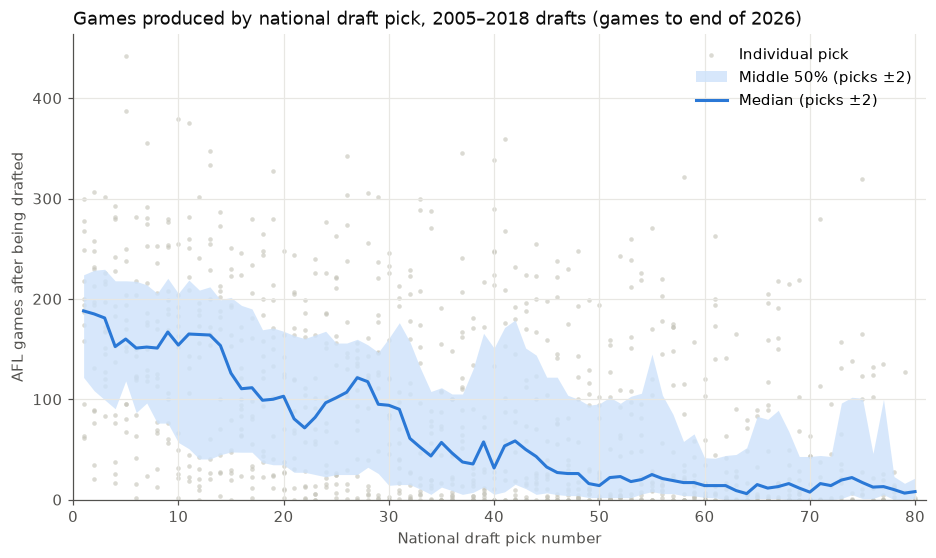

In [8]:
# Chart colours: grey for context, blue for the typical curve, orange for emphasis
GREY = "#c3c2b7"
BLUE = "#2a78d6"
BLUE_BAND = "#cde2fb"
ORANGE = "#eb6834"
INK = "#52514e"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": INK,
    "axes.labelcolor": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "axes.grid": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
})


def draw_curve(ax):
    """All picks as grey dots, with the smoothed median and middle-50% band."""
    shown = matched[matched["pick"] <= MAX_PICK]
    ax.scatter(shown["pick"], shown["games_after_draft"], s=9, color=GREY,
               alpha=0.6, linewidths=0, label="Individual pick")
    ax.fill_between(curve["pick"], curve["q25"], curve["q75"], color=BLUE_BAND,
                    alpha=0.8, linewidth=0, label="Middle 50% (picks ±2)")
    ax.plot(curve["pick"], curve["median"], color=BLUE, linewidth=2,
            label="Median (picks ±2)")
    ax.set_xlim(0, MAX_PICK + 1)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("National draft pick number")
    ax.set_ylabel("AFL games after being drafted")


fig, ax = plt.subplots(figsize=(10, 5.5))
draw_curve(ax)
ax.set_title(f"Games produced by national draft pick, {FIRST_DRAFT}–{LAST_DRAFT} drafts "
             f"(games to end of {LAST_SEASON})", loc="left", color="#0b0b0b")
ax.legend(frameon=False, loc="upper right")
plt.show()

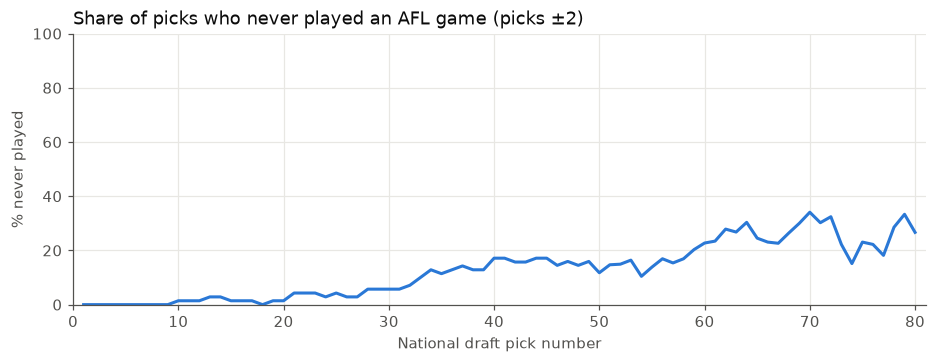

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(curve["pick"], curve["share_never_played"] * 100, color=BLUE, linewidth=2)
ax.set_xlim(0, MAX_PICK + 1)
ax.set_ylim(0, 100)
ax.set_xlabel("National draft pick number")
ax.set_ylabel("% never played")
ax.set_title("Share of picks who never played an AFL game (picks ±2)",
             loc="left", color="#0b0b0b")
plt.show()

### A caveat: careers aren't finished

Someone drafted in 2005 has had up to 21 seasons, while a 2018 draftee has had
only 8, and many of them are still playing. If later drafts look worse, that is
at least partly this effect, not worse drafting.

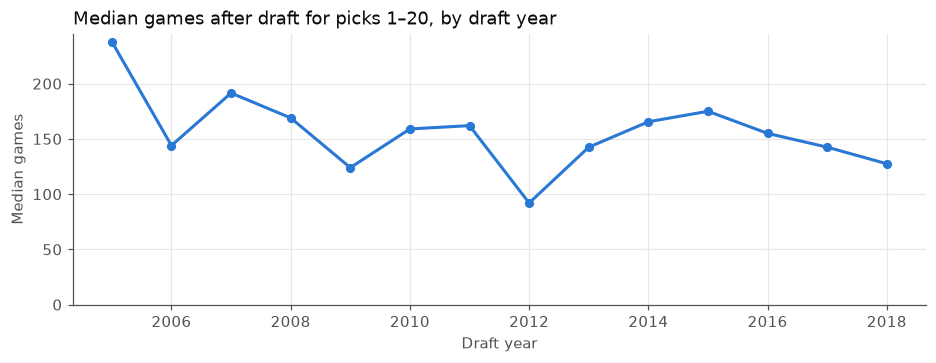

draft_year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
median,238.0,144.0,191.5,169.0,124.0,159.0,162.0,92.0,142.5,165.5,175.0,155.0,142.5,127.5
mean,188.9,156.4,182.0,155.0,134.4,151.9,148.8,133.4,129.8,124.4,163.6,144.0,121.6,111.3
count,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0


In [10]:
by_year = (matched[matched["pick"] <= 20]
           .groupby("draft_year")["games_after_draft"]
           .agg(["median", "mean", "count"]))

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(by_year.index, by_year["median"], color=BLUE, linewidth=2, marker="o", markersize=5)
ax.set_xlabel("Draft year")
ax.set_ylabel("Median games")
ax.set_title("Median games after draft for picks 1–20, by draft year",
             loc="left", color="#0b0b0b")
ax.set_ylim(bottom=0)
plt.show()
by_year.round(1).T

## 4. Port Adelaide's picks against the curve

The "expected" figure for each Port pick is the curve's median at that pick
number. *Games for Port* shows how much of the value Port kept. Academy and
father-son picks are flagged, because a bid-matched pick number doesn't mean
the same thing as an open pick.

In [11]:
port = matched[matched["club"] == "Port Adelaide"].copy()
port["expected_games"] = port["pick"].map(curve.set_index("pick")["median"])
port["vs_expected"] = port["games_after_draft"] - port["expected_games"]

print(f"Port Adelaide national draft picks {FIRST_DRAFT}-{LAST_DRAFT}: {len(port)}")
port[["draft_year", "pick", "player", "signing", "games_after_draft",
      "games_for_drafting_club", "expected_games", "vs_expected"]].rename(
    columns={"games_after_draft": "games", "games_for_drafting_club": "games for Port"}
)

Port Adelaide national draft picks 2005-2018: 59


,draft_year,pick,player,signing,games,games for Port,expected_games,vs_expected
29,2005,30,Nick Lower,,55,20,94.0,-39.0
43,2005,44,Alipate Carlile,,167,167,43.0,124.0
56,2005,58,Hugh Minson,,0,0,17.0,-17.0
64,2005,70,Jonathan Giles,,63,0,7.5,55.5
70,2006,5,Travis Boak,,387,387,160.0,227.0
88,2006,23,Paul Stewart,,101,101,82.0,19.0
104,2006,39,Nathan Krakouer,,82,69,57.5,24.5
120,2006,55,Robbie Gray,,271,271,25.0,246.0
135,2006,71,Justin Westhoff,,280,280,16.0,264.0
143,2006,83,Ryan Williams,,2,2,NaN,NaN


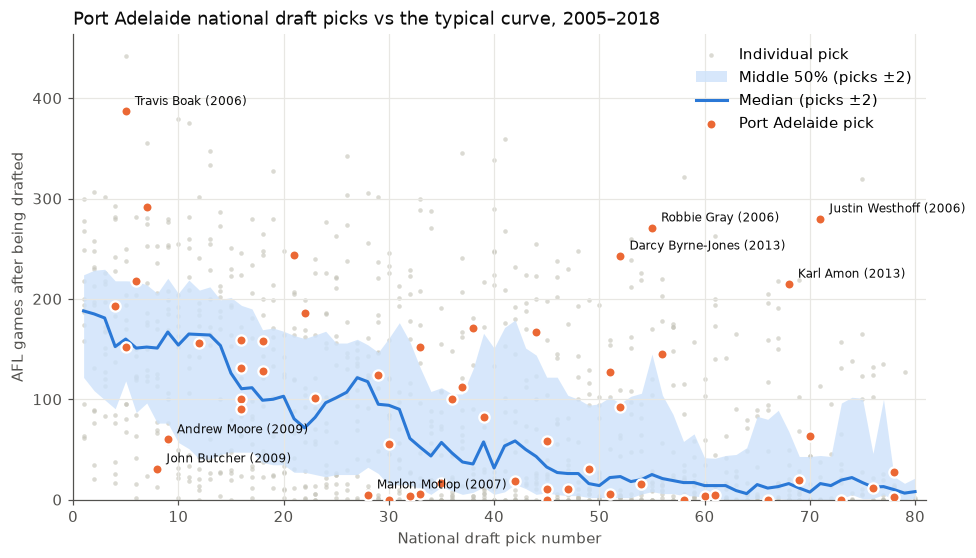

In [12]:
fig, ax = plt.subplots(figsize=(10, 5.5))
draw_curve(ax)

port_shown = port[port["pick"] <= MAX_PICK]
ax.scatter(port_shown["pick"], port_shown["games_after_draft"], s=45, color=ORANGE,
           edgecolors="white", linewidths=1.5, zorder=3, label="Port Adelaide pick")

# Label the picks furthest above and below the curve
to_label = pd.concat([port_shown.nlargest(5, "vs_expected"),
                      port_shown.nsmallest(3, "vs_expected")])
for row in to_label.itertuples():
    ax.annotate(f"{row.player} ({row.draft_year})", (row.pick, row.games_after_draft),
                xytext=(6, 4), textcoords="offset points", fontsize=8, color="#0b0b0b")

ax.set_title(f"Port Adelaide national draft picks vs the typical curve, "
             f"{FIRST_DRAFT}–{LAST_DRAFT}", loc="left", color="#0b0b0b")
ax.legend(frameon=False, loc="upper right")
plt.show()

### Putting Port in context: every club measured the same way

Adding up Port's games and comparing that with the sum of the medians would
flatter **any** club. Games are right-skewed (lots of zeros, a few 300-game
careers), so the average sits above the median for everyone. So here every
club gets the same measure, using picks 1–80, which is where the curve exists.

The skew is much stronger for late picks: around pick 40–80 the mean is 2.5–3×
the median. A median-based "expected" therefore rewards clubs that drafted late
and landed one or two long careers. So I show two versions:

- **vs median**: total games ÷ sum of the median at each pick
- **vs mean**: total games ÷ sum of the mean at each pick (less biased by pick position; plotted below)
- **share above median**: the fraction of a club's picks that beat the median for their pick number (about 50% is typical by construction)
- **share kept**: the fraction of those games played for the drafting club

In [13]:
in_range = matched[matched["pick"] <= MAX_PICK].copy()
in_range["expected_median"] = in_range["pick"].map(curve.set_index("pick")["median"])
in_range["expected_mean"] = in_range["pick"].map(curve.set_index("pick")["mean"])
in_range["above_median"] = in_range["games_after_draft"] > in_range["expected_median"]

clubs = in_range.groupby("club").agg(
    picks=("pick", "size"),
    average_pick=("pick", "mean"),
    games=("games_after_draft", "sum"),
    expected_median=("expected_median", "sum"),
    expected_mean=("expected_mean", "sum"),
    share_above_median=("above_median", "mean"),
    games_for_club=("games_for_drafting_club", "sum"),
)
clubs["vs_median"] = clubs["games"] / clubs["expected_median"]
clubs["vs_mean"] = clubs["games"] / clubs["expected_mean"]
clubs["share_kept"] = clubs["games_for_club"] / clubs["games"]
clubs = clubs.sort_values("vs_mean")

print("Correlation of club's average pick with each ratio:")
print(f"  vs median: {clubs['average_pick'].corr(clubs['vs_median']):.2f}")
print(f"  vs mean:   {clubs['average_pick'].corr(clubs['vs_mean']):.2f}")
clubs.sort_values("vs_mean", ascending=False).drop(
    columns=["expected_median", "expected_mean", "games_for_club"]).round(2)

Correlation of club's average pick with each ratio:
  vs median: 0.78
  vs mean:   0.57


,picks,average_pick,games,share_above_median,vs_median,vs_mean,share_kept
club,,,,,,,
Hawthorn,49,41.43,4746,0.51,1.77,1.18,0.74
Western Bulldogs,60,38.38,6064,0.50,1.49,1.13,0.74
Port Adelaide,56,39.21,5441,0.54,1.55,1.12,0.84
Adelaide,51,39.22,4935,0.43,1.40,1.12,0.70
Geelong,61,42.89,5345,0.54,1.69,1.11,0.74
Sydney,51,38.90,4827,0.51,1.53,1.11,0.67
Melbourne,60,35.63,5928,0.55,1.35,1.05,0.81
Collingwood,55,39.75,4915,0.55,1.35,1.02,0.82
North Melbourne,60,38.65,5185,0.50,1.35,1.01,0.90


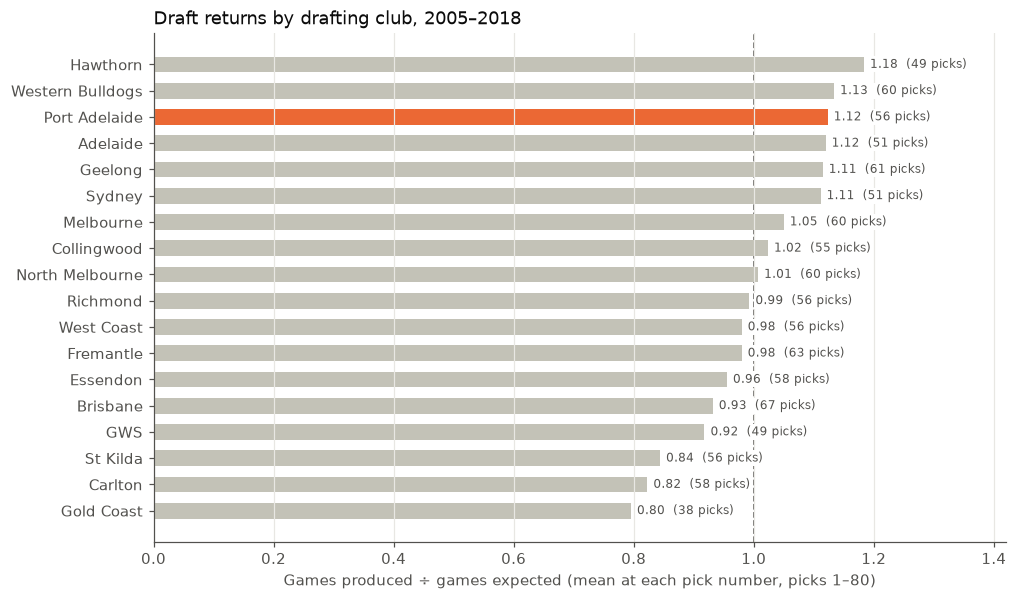

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
colours = [ORANGE if club == "Port Adelaide" else GREY for club in clubs.index]
ax.barh(clubs.index, clubs["vs_mean"], color=colours, height=0.6)
ax.axvline(1, color=INK, linewidth=1, linestyle="--", zorder=0)
for y, (club, row) in enumerate(clubs.iterrows()):
    ax.annotate(f"{row['vs_mean']:.2f}  ({int(row['picks'])} picks)",
                (row["vs_mean"], y), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK,
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.grid(axis="y", visible=False)
ax.set_xlim(0, clubs["vs_mean"].max() * 1.2)
ax.set_xlabel("Games produced ÷ games expected (mean at each pick number, picks 1–80)")
ax.set_title(f"Draft returns by drafting club, {FIRST_DRAFT}–{LAST_DRAFT}",
             loc="left", color="#0b0b0b")
plt.show()

## 5. Observations (exploratory, no conclusions yet)


These are things I noticed, not conclusions. Each one could become a hypothesis to test properly.

### Data quality
- **1,028 national picks** (2005–2018). 117 (11%) never played an AFL game.
- **Match rate: 898 of 911 picks who played (98.6%).** The 12 unmatched are all
  nickname variants (Nathan/Nat Fyfe, Brad/Bradley Hill, Harrison/Harry Petty…),
  plus one accent ("Ó hAilpín"). One pick is genuinely ambiguous: Alwyn Davey senior
  and junior both played for Essendon. None of these have been resolved by guessing.
- **The two sources agree on all 898 matched picks**, once games are counted
  *after* the draft. DraftGuru's games figure means "games after this selection",
  not lifetime career games. The two differ only for recycled players.

### The pick curve
- The median runs at **about 150–190 games through pick ~14**, then falls in steps:
  about 100 by pick 20, roughly 30–60 across picks 33–45, and at most 25 from pick 49 onwards.
- The drops around picks 14–16 and 30–33 might be real (end of the first round?) or
  noise. Each point rests on about 70 players, so the steps could be tested by bootstrapping.
- **The spread is very wide everywhere.** At pick 10 the middle 50% runs from 57 to
  206 games. 18 picks after pick 50 played 200+ games.
- **Late picks behave like lottery tickets.** Beyond pick ~20 the mean is well above
  the median (2.5–3× at picks 40–80): most late picks play little, and a few play a lot.
  All 140 top-10 picks played at least once; 20–35% of picks after 55 never did.
- **Careers aren't finished.** For picks 1–20 the mean drops from 189 games (2005
  draft) to 111 (2018). Some of that is year-to-year noise (the 2012 median is the
  lowest), but recent drafts are clearly undercounted.

### Port Adelaide
- **59 national picks:** 14 in the top 20 and 30 after pick 40. According to DraftGuru,
  none were academy or father-son picks in this window.
- **Well above the curve:** late picks Justin Westhoff (pick 71, 280 games), Robbie Gray
  (55, 271), Darcy Byrne-Jones (52, 243) and Karl Amon (68, 215), plus Travis Boak
  (5, 387). All five came from just two drafts: 2006 (Boak, Gray, Westhoff) and 2013 (Byrne-Jones, Amon).
- **Well below the curve:** the 2009 top-10 pair John Butcher (pick 8, 31 games) and
  Andrew Moore (9, 60), Marlon Motlop (28, 5) and Mason Shaw (30, 0).
- **Port ranks 3rd of 18 on both benchmarks** (1.12× the mean-based expectation;
  54% of picks beat the median for their slot). Port also **kept 84% of the games its
  draftees played**, the 4th-highest retention of 18 clubs (range 61–90%).
- **The choice of benchmark matters.** Under the median-based ratio, clubs that drafted
  late look much better (correlation with average pick 0.78, falling to 0.57 with the
  mean-based ratio). Geelong moves from 2nd to 5th and Fremantle from 7th to 12th.
  Port's position holds under both.

### Caveats to keep in mind
- Games played is a proxy for value: it doesn't capture quality or role.
- Clubs trade picks, so "drafting club" isn't always the club that originally earned the pick.
- Only the national draft is included. Rookie, pre-season and mid-season selections aren't.
- With 40–60 picks per club, a couple of outliers can move a club's ranking a long way.

### Possible directions to discuss
1. Fix the censoring: count games in each player's **first N seasons** (the AFL Tables
   season data supports this for the 98.6% matched), so every draft year is compared fairly.
2. Define pick value as **probability of reaching a threshold** (e.g. 50 or 100 games)
   rather than median games, to deal with the lottery-ticket shape of late picks.
3. Test whether Port's result is **robust or driven by one or two drafts** (e.g. leave out 2006).
4. Compare the empirical curve with the AFL's official **draft points index** used for academy bids.